<a href="https://colab.research.google.com/github/soleildayana/Data-Mining/blob/main/StellarMovingGroups_AgeEstimation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Determinación de la Edad Cinemática de Grupos Móviles Jóvenes
Proyecto 3 para el curso de Minería de Datos en Astronomía

**Soleil Dayana Niño Murcia**

---

## Introducción y Resumen- El Desafío de Medir el Tiempo Estelar

¿Cuándo nace realmente una asociación de estrellas y cómo podemos demostrar que alguna vez compartieron un mismo volumen de espacio infinitesimal? En astrofísica estelar, las edades de las poblaciones jóvenes ($	au < 20\text{ Myr}$) suelen estimarse mediante el ajuste de isócronas en diagramas color-magnitud. No obstante, este método evolutivo arrastra severas incertidumbres ligadas a los modelos de opacidad molecular, el enrojecimiento interestelar y la dispersión por binariedad no resuelta.

Este proyecto aborda una alternativa puramente física: la **edad cinemática**. Bajo la hipótesis de que las estrellas de un grupo móvil joven se formaron en un evento de colapso coherente y posteriormente comenzaron una expansión libre (despreciando el potencial gravitacional galáctico a escalas de tiempo tan cortas), realizamos una integración orbital hacia el pasado (*Kinematic Traceback*) en coordenadas cartesianas 6D $(x, y, z, v_x, v_y, v_z)$ utilizando datos de alta precisión de **Gaia DR3** cruzados con catálogos de **Simbad**.

### Lo que este trabajo revela de forma crítica:
* **La ilusión del tiempo cero:** Demostramos que, mientras que para el grupo más cercano (**TWA**, $d \sim 55\text{ pc}$) la métrica robusta $\text{MAD}_{3D}$ logra resolver un mínimo de dispersión coherente en **$4.71 \pm 3.00\text{ Myr}$** (acercándose al límite inferior isocronal), para grupos más distantes o compactos (**$\eta$ Cha** y **USco**), la dispersión observacional —particularmente el ruido instrumental en las velocidades radiales de Gaia— domina por completo la señal de expansión, atrapando artificialmente los mínimos de dispersión en el presente ($t \approx 0$).
* **El dilema de la contaminación cinemática:** Al aplicar modelos de mezclas gaussianas (GMM) para identificar de forma no supervisada nuevos candidatos, nos enfrentamos a que de un puñado de miembros confirmados pasemos a cientos de candidatos. Esto no refleja necesariamente una población masiva oculta, sino la inevitabilidad de que gaussianas en 6D absorban estrellas del disco joven local que simplemente comparten la corriente de movimiento del entorno solar cercano.

A continuación, se despliega el desarrollo técnico estructurado en cuatro etapas, desde la minería de datos TAP en servidores espejo hasta la clasificación multidimensional no supervisada.

## Metodología

### Etapa 1: Selección de los Grupos, Consulta (Simbad + Gaia TAP) y *Cross-Match*

Reconstruir las posiciones pasadas de una asociación estelar exige conocer sus tres coordenadas espaciales y sus tres componentes de velocidad $(x, y, z, v_x, v_y, v_z)$. Como solo una fracción de las estrellas en **Gaia DR3** cuenta con velocidad radial espectroscópica, conviene trabajar con grupos jóvenes ($\tau < 20\text{ Myr}$) cercanos y bien documentados:

1. **TW Hydrae association (TWA):** Edad $\approx 8\text{--}10\text{ Myr}$, distancia media $\sim 55\text{ pc}$ ($\varpi \approx 18\text{ mas}$).
2. **$\eta$ Chamaeleontis cluster ($\eta$ Cha):** Edad $\approx 8\text{--}11\text{ Myr}$, distancia media $\sim 95\text{ pc}$ ($\varpi \approx 10.5\text{ mas}$).
3. **Upper Scorpius (USco):** Edad $\approx 10\text{--}11\text{ Myr}$, distancia media $\sim 145\text{ pc}$ ($\varpi \approx 6.9\text{ mas}$).

Para evitar interrupciones en los servidores principales, las consultas ADQL se dirigen a los espejos de **Simbad Harvard** (`simbad.harvard.edu`) y **ARI Heidelberg** (`gaia.ari.uni-heidelberg.de`), guardando copias locales en `.csv`.

In [ ]:
%pip install astroquery plotly -Uq

In [22]:
# Librerías
import os
import urllib.parse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from astroquery.simbad import Simbad
import astropy.units as u
from astropy.coordinates import SkyCoord
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.dpi"] = 110
sns.set_style("whitegrid")

# PARÁMETROS de los 3 grupos
CONFIG_GRUPOS = {
    "twa": {
        "nombre": "TW Hydrae (TWA)",
        "edad_lit": "8 - 10 Myr",
        "ra": 165.0, "dec": -34.0, "radio": 25.0,
        "plx_min": 10.0, "plx_max": 30.0,
        "simbad_like": "ident.id LIKE 'TWA %'",
        # TWA usa respaldo pre-descargado porque el cono de 25° tiende a timeout en TAP
        "url_respaldo_gaia": "https://raw.githubusercontent.com/soleildayana/Data-Mining/main/gaia_twa.csv",
        "gmm_k": 4,
        "color": "#ff595e"
    },
    "etacha": {
        "nombre": r"$\eta$ Chamaeleontis ($\eta$ Cha)",
        "edad_lit": "8 - 11 Myr",
        "ra": 130.5, "dec": -79.0, "radio": 5.0,
        "plx_min": 7.0, "plx_max": 15.0,
        "simbad_like": "ident.id LIKE 'RECX %' OR ident.id LIKE 'eta Cha %'",
        "url_respaldo_gaia": None,
        "gmm_k": 3,
        "color": "#52b788"
    },
    "usco": {
        "nombre": "Upper Scorpius (USco)",
        "edad_lit": "10 - 11 Myr",
        "ra": 243.0, "dec": -23.0, "radio": 6.0,
        "plx_min": 5.5, "plx_max": 9.5,
        "simbad_like": "ident.id LIKE 'UScoCTIO %' OR ident.id LIKE 'RX J16%'",
        "url_respaldo_gaia": None,
        "gmm_k": 2,
        "color": "#4ea8de"
    }
}

Función de descarga:

In [4]:
def descargar_datos_grupo(grupo, cfg):
    """Descarga y guarda localmente las tablas de Simbad y Gaia DR3 para un grupo."""
    archivo_simbad = f"simbad_{grupo}.csv"
    archivo_gaia = f"gaia_{grupo}.csv"

    # 1. Consulta Simbad TAP (espejo Harvard)
    if not os.path.exists(archivo_simbad):
        simbad_client = Simbad()
        simbad_client.server = "simbad.harvard.edu"
        query_simbad = f"""
            SELECT DISTINCT basic.oid, basic.main_id, basic.ra, basic.dec, ident.id AS gaia_id
            FROM basic
            JOIN ident ON basic.oid = ident.oidref
            WHERE basic.oid IN (SELECT oidref FROM ident WHERE {cfg['simbad_like']})
            AND ident.id LIKE 'Gaia DR3 %'
        """
        tabla_simbad = simbad_client.query_tap(query_simbad)
        tabla_simbad.write(archivo_simbad, format="csv", overwrite=True)

    # 2. Consulta Gaia DR3 TAP (espejo ARI Heidelberg o respaldo)
    if not os.path.exists(archivo_gaia):
        if cfg["url_respaldo_gaia"] is not None:
            df_gaia = pd.read_csv(cfg["url_respaldo_gaia"])
            df_gaia.to_csv(archivo_gaia, index=False)
        else:
            endpoint_ari = "https://gaia.ari.uni-heidelberg.de/tap/sync"
            adql_gaia = f"""
                SELECT source_id, ra, dec, parallax, parallax_error,
                       pmra, pmra_error, pmdec, pmdec_error,
                       radial_velocity, radial_velocity_error
                FROM gaiadr3.gaia_source
                WHERE 1 = CONTAINS(
                    POINT('ICRS', ra, dec),
                    CIRCLE('ICRS', {cfg['ra']}, {cfg['dec']}, {cfg['radio']})
                )
                AND parallax BETWEEN {cfg['plx_min']} AND {cfg['plx_max']}
                AND radial_velocity IS NOT NULL
            """
            url = f"{endpoint_ari}?request=doQuery&lang=ADQL&format=csv&query={urllib.parse.quote(adql_gaia)}"
            df_gaia = pd.read_csv(url)
            df_gaia.to_csv(archivo_gaia, index=False)

    return pd.read_csv(archivo_simbad), pd.read_csv(archivo_gaia)

Ejecución de la descarga y cross-match (puede tardar ~3min la primera vez)

In [6]:
datos_grupos = {}
resumen_cruce = []

for grupo, cfg in CONFIG_GRUPOS.items():
    df_simbad, df_gaia = descargar_datos_grupo(grupo, cfg) # Se llama la función de descarga

    ids_simbad = (
        df_simbad["gaia_id"]
        .astype(str)
        .str.replace("Gaia DR3 ", "", regex=False)
        .str.strip()
        .astype("int64")
    )

    df_gaia["es_miembro_simbad"] = df_gaia["source_id"].isin(ids_simbad)
    datos_grupos[grupo] = df_gaia

    resumen_cruce.append({
        "Grupo": grupo.upper(),
        "Catalogados Simbad (ID Gaia)": len(set(ids_simbad)),
        "Estrellas en cono Gaia (con RV)": len(df_gaia),
        "Miembros Simbad cruzados": int(df_gaia["es_miembro_simbad"].sum()),
        "Fuera del cono o sin RV": len(set(ids_simbad) - set(df_gaia["source_id"]))
    })

pd.DataFrame(resumen_cruce)

,Grupo,Catalogados Simbad (ID Gaia),Estrellas en cono Gaia (con RV),Miembros Simbad cruzados,Fuera del cono o sin RV
0,TWA,58,5534,25,33
1,ETACHA,18,681,10,8
2,USCO,800,2279,78,722


Visualicemos la distribución de los datos recién descargados para explorar de forma interactiva la geometría, distancia y densidad de cada grupo:

In [7]:
# Exploración espacial 3D (ICRS) de los datos recién descargados (antes de filtrar)
dfs_raw_3d = []

for grupo, cfg in CONFIG_GRUPOS.items():
    df_tmp = datos_grupos[grupo].copy()
    df_tmp = df_tmp[df_tmp["parallax"] > 0].copy()

    coords_raw = SkyCoord(
        ra=df_tmp["ra"].values * u.deg,
        dec=df_tmp["dec"].values * u.deg,
        distance=(1000.0 / df_tmp["parallax"].values) * u.pc,
        frame="icrs"
    )
    df_tmp["x_raw"] = coords_raw.cartesian.x.to_value(u.pc)
    df_tmp["y_raw"] = coords_raw.cartesian.y.to_value(u.pc)
    df_tmp["z_raw"] = coords_raw.cartesian.z.to_value(u.pc)
    df_tmp["Etiqueta"] = np.where(
        df_tmp["es_miembro_simbad"],
        f"{grupo.upper()} — Miembro Simbad",
        f"{grupo.upper()} — Cono Gaia sin filtrar"
    )
    dfs_raw_3d.append(df_tmp)

df_raw_total = pd.concat(dfs_raw_3d, ignore_index=True)

fig_raw_3d = go.Figure()

estilos_raw = {
    "TWA — Cono Gaia sin filtrar":    dict(color="#ff595e", size=2.2, opacity=0.22, symbol="circle"),
    "TWA — Miembro Simbad":           dict(color="#ffd166", size=6.5, opacity=1.00, symbol="diamond"),
    "ETACHA — Cono Gaia sin filtrar": dict(color="#52b788", size=2.5, opacity=0.30, symbol="circle"),
    "ETACHA — Miembro Simbad":        dict(color="#06d6a0", size=6.5, opacity=1.00, symbol="diamond"),
    "USCO — Cono Gaia sin filtrar":   dict(color="#4ea8de", size=2.2, opacity=0.22, symbol="circle"),
    "USCO — Miembro Simbad":          dict(color="#ffffff", size=6.5, opacity=1.00, symbol="diamond"),
}

for etiqueta, st in estilos_raw.items():
    sub = df_raw_total[df_raw_total["Etiqueta"] == etiqueta]
    fig_raw_3d.add_trace(go.Scatter3d(
        x=sub["x_raw"], y=sub["y_raw"], z=sub["z_raw"],
        mode="markers",
        name=f"{etiqueta} (n={len(sub)})",
        marker=dict(size=st["size"], color=st["color"], opacity=st["opacity"], symbol=st["symbol"]),
        customdata=np.stack([sub["source_id"], sub["parallax"]], axis=-1),
        hovertemplate="<b>%{fullData.name}</b><br>X: %{x:.1f} pc<br>Y: %{y:.1f} pc<br>Z: %{z:.1f} pc<br>Gaia ID: %{customdata[0]}<br>Plx: %{customdata[1]:.2f} mas<extra></extra>"
    ))

# Posición del Sol en el origen (0, 0, 0)
fig_raw_3d.add_trace(go.Scatter3d(
    x=[0], y=[0], z=[0], mode="markers+text", name="Sol (ICRS origen)",
    text=["Sol"], textposition="top center",
    marker=dict(size=7, color="#ffbe0b", symbol="cross")
))

fig_raw_3d.update_layout(
    title="Volúmenes de Búsqueda en Gaia DR3 antes de Limpiar (Coordenadas ICRS)",
    paper_bgcolor="black",
    plot_bgcolor="black",
    font=dict(color="white"),
    scene=dict(
        bgcolor="black",
        xaxis=dict(title="X [pc]", gridcolor="#2b2d42", zerolinecolor="#4a4e69", backgroundcolor="black"),
        yaxis=dict(title="Y [pc]", gridcolor="#2b2d42", zerolinecolor="#4a4e69", backgroundcolor="black"),
        zaxis=dict(title="Z [pc]", gridcolor="#2b2d42", zerolinecolor="#4a4e69", backgroundcolor="black"),
    ),
    legend=dict(bgcolor="rgba(15,15,20,0.85)", bordercolor="#4a4e69", borderwidth=1),
    height=620
)
fig_raw_3d.show()

### Etapa 2: Limpieza Astrométrica y Transformación 6D en ICRS

Antes de proyectar las estrellas al espacio cartesiano, se depuran las tablas descargadas mediante dos criterios:

1. **Filtros de error relativo:** Se descartan fuentes con incertidumbres relativas elevadas en paralaje ($\sigma_\varpi / \varpi \ge 10\%$), movimiento propio ($\sigma_{\mu} / |\mu| \ge 10\%$) y velocidad radial ($\sigma_{v_r} / |v_r| \ge 20\%$):
   * **Paralaje ($< 10\%$):** Como $d = 1000/\varpi$ es una relación inversa no lineal, errores mayores al $10\%$ vuelven asimétrica la distribución de distancias y deforman tanto las posiciones $(x, y, z)$ como las velocidades tangenciales ($v_t = 4.74\,\mu/\varpi$).
   * **Movimiento propio ($< 10\%$):** Las asociaciones jóvenes cercanas tienen movimientos propios altos y bien definidos ($\sim 20\text{--}100\text{ mas/yr}$), por lo que este corte conserva precisión en el plano del cielo sin sacrificar demasiadas fuentes.
   * **Velocidad radial ($< 20\%$):** Al integrar hacia el pasado, el error en velocidad crece linealmente con el tiempo ($\Delta r \approx 1.023\,\Delta v \cdot t\text{ [pc]}$). Se fija un umbral más holgado ($20\%$) porque las velocidades radiales espectroscópicas en Gaia DR3 arrastran mayor ruido instrumental que la astrometría, evitando dejar sin muestra a grupos pequeños como $\eta$ Cha.
2. **Filtro de *outliers* en observables:** Sobre los miembros confirmados de cada grupo se aplica el criterio del rango intercuartílico ($1.5 \times \text{IQR}$) en **paralaje ($\varpi$), movimiento propio ($\mu_\alpha^*, \mu_\delta$) y velocidad radial ($v_r$)**, descartando objetos de fondo o posibles binarias con velocidades desplazadas.

Con `astropy.coordinates.SkyCoord` se transforman las observables limpias a posiciones $(x, y, z)$ en $\text{pc}$ y velocidades $(v_x, v_y, v_z)$ en $\text{km/s}$ dentro del sistema **ICRS**.

In [8]:
def limpiar_y_transformar_icrs(df, max_err_plx=0.10, max_err_pm=0.10, max_err_rv=0.20):
    """
    Filtra fuentes por errores relativos y elimina outliers (1.5 * IQR) en paralaje,
    movimiento propio y velocidad radial sobre los miembros de Simbad.
    Transforma las observables a coordenadas cartesianas 6D en ICRS.
    """
    df_clean = df.copy()

    # Evitar divisiones por cero o paralajes no positivas
    validos = (
        (df_clean["parallax"] > 0) &
        (df_clean["pmra"].abs() > 0) &
        (df_clean["pmdec"].abs() > 0) &
        (df_clean["radial_velocity"].abs() > 0)
    )
    df_clean = df_clean[validos].copy()

    # 1. Filtros de error relativo en paralaje, movimiento propio y velocidad radial
    cond_errores = (
        ((df_clean["parallax_error"] / df_clean["parallax"]) < max_err_plx) &
        ((df_clean["pmra_error"] / df_clean["pmra"].abs()) < max_err_pm) &
        ((df_clean["pmdec_error"] / df_clean["pmdec"].abs()) < max_err_pm) &
        ((df_clean["radial_velocity_error"] / df_clean["radial_velocity"].abs()) < max_err_rv)
    )
    df_clean = df_clean[cond_errores].copy()

    # 2. Filtro de outliers (1.5 * IQR) en paralaje, movimiento propio y velocidad radial
    cols_iqr = ["parallax", "pmra", "pmdec", "radial_velocity"]
    es_outlier_mem = pd.Series(False, index=df_clean.index)

    for col in cols_iqr:
        vals_mem = df_clean.loc[df_clean["es_miembro_simbad"], col]
        q1, q3 = vals_mem.quantile([0.25, 0.75])
        iqr = q3 - q1
        if iqr > 0:
            lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            es_outlier_mem |= df_clean["es_miembro_simbad"] & (~df_clean[col].between(lim_inf, lim_sup))

    df_clean = df_clean[~es_outlier_mem].copy()

    # 3. Conversión a coordenadas cartesianas 6D en ICRS
    coords = SkyCoord(
        ra=df_clean["ra"].values * u.deg,
        dec=df_clean["dec"].values * u.deg,
        distance=(1000.0 / df_clean["parallax"].values) * u.pc,
        pm_ra_cosdec=df_clean["pmra"].values * (u.mas / u.yr),
        pm_dec=df_clean["pmdec"].values * (u.mas / u.yr),
        radial_velocity=df_clean["radial_velocity"].values * (u.km / u.s),
        frame="icrs"
    )

    df_clean["x"] = coords.cartesian.x.to_value(u.pc)
    df_clean["y"] = coords.cartesian.y.to_value(u.pc)
    df_clean["z"] = coords.cartesian.z.to_value(u.pc)
    df_clean["vx"] = coords.velocity.d_x.to_value(u.km / u.s)
    df_clean["vy"] = coords.velocity.d_y.to_value(u.km / u.s)
    df_clean["vz"] = coords.velocity.d_z.to_value(u.km / u.s)

    return df_clean


datos_limpios = {}
miembros_limpios = {}
resumen_limpieza = []

for grupo in CONFIG_GRUPOS:
    df_raw = datos_grupos[grupo]
    df_clean = limpiar_y_transformar_icrs(df_raw)
    df_mem = df_clean[df_clean["es_miembro_simbad"]].copy()

    datos_limpios[grupo] = df_clean
    miembros_limpios[grupo] = df_mem

    resumen_limpieza.append({
        "Grupo": grupo.upper(),
        "Cono inicial": len(df_raw),
        "Cono tras limpieza": len(df_clean),
        "Miembros Simbad iniciales": int(df_raw["es_miembro_simbad"].sum()),
        "Miembros Simbad limpios": len(df_mem)
    })

pd.DataFrame(resumen_limpieza)

,Grupo,Cono inicial,Cono tras limpieza,Miembros Simbad iniciales,Miembros Simbad limpios
0,TWA,5534,3726,25,8
1,ETACHA,681,441,10,4
2,USCO,2279,1077,78,21


### Etapa 3: *Kinematic Traceback* y Comparación de Métricas ($R_{\text{RMS}}$ vs. $\text{MAD}_{3D}$)

Como las edades buscadas ($\tau < 20\text{ Myr}$) son mucho menores que el período orbital galáctico ($T_{\text{gal}} \approx 220\text{ Myr}$), se desprecia la aceleración diferencial de la Galaxia y se integran las trayectorias hacia el pasado bajo movimiento rectilíneo uniforme:
$$\mathbf{r}_i(t) = \mathbf{r}_{i,0} + \mathbf{v}_{i,0}\, t, \qquad t \le 0$$

La edad cinemática $\tau_{\text{kin}}$ corresponde al instante pasado en el que la dispersión espacial del grupo alcanza su mínimo. Para cuantificar la dispersión en cada paso temporal se evalúan dos métricas complementarias:
* **$R_{\text{RMS}}(t)$:** Radio cuadrático medio respecto a la mediana espacial del grupo; pondera por igual los cuadrados de todas las distancias al centro, por lo que basta una estrella con velocidad atípica para desplazar el mínimo.
* **$\text{MAD}_{3D}(t)$:** Desviación absoluta mediana escalada en 3D (factor $1.4826$); sigue la contracción del núcleo denso del grupo sin dejarse arrastrar por extremos.

**Estimación de incertidumbres:** Para ambas métricas se aplica un remuestreo *Bootstrap* no paramétrico ($1,000$ iteraciones con reemplazo sobre los $N$ miembros de cada asociación). La desviación estándar de las edades obtenidas en las $1,000$ muestras mide qué tan sensible es el mínimo de dispersión a la composición exacta de la muestra.

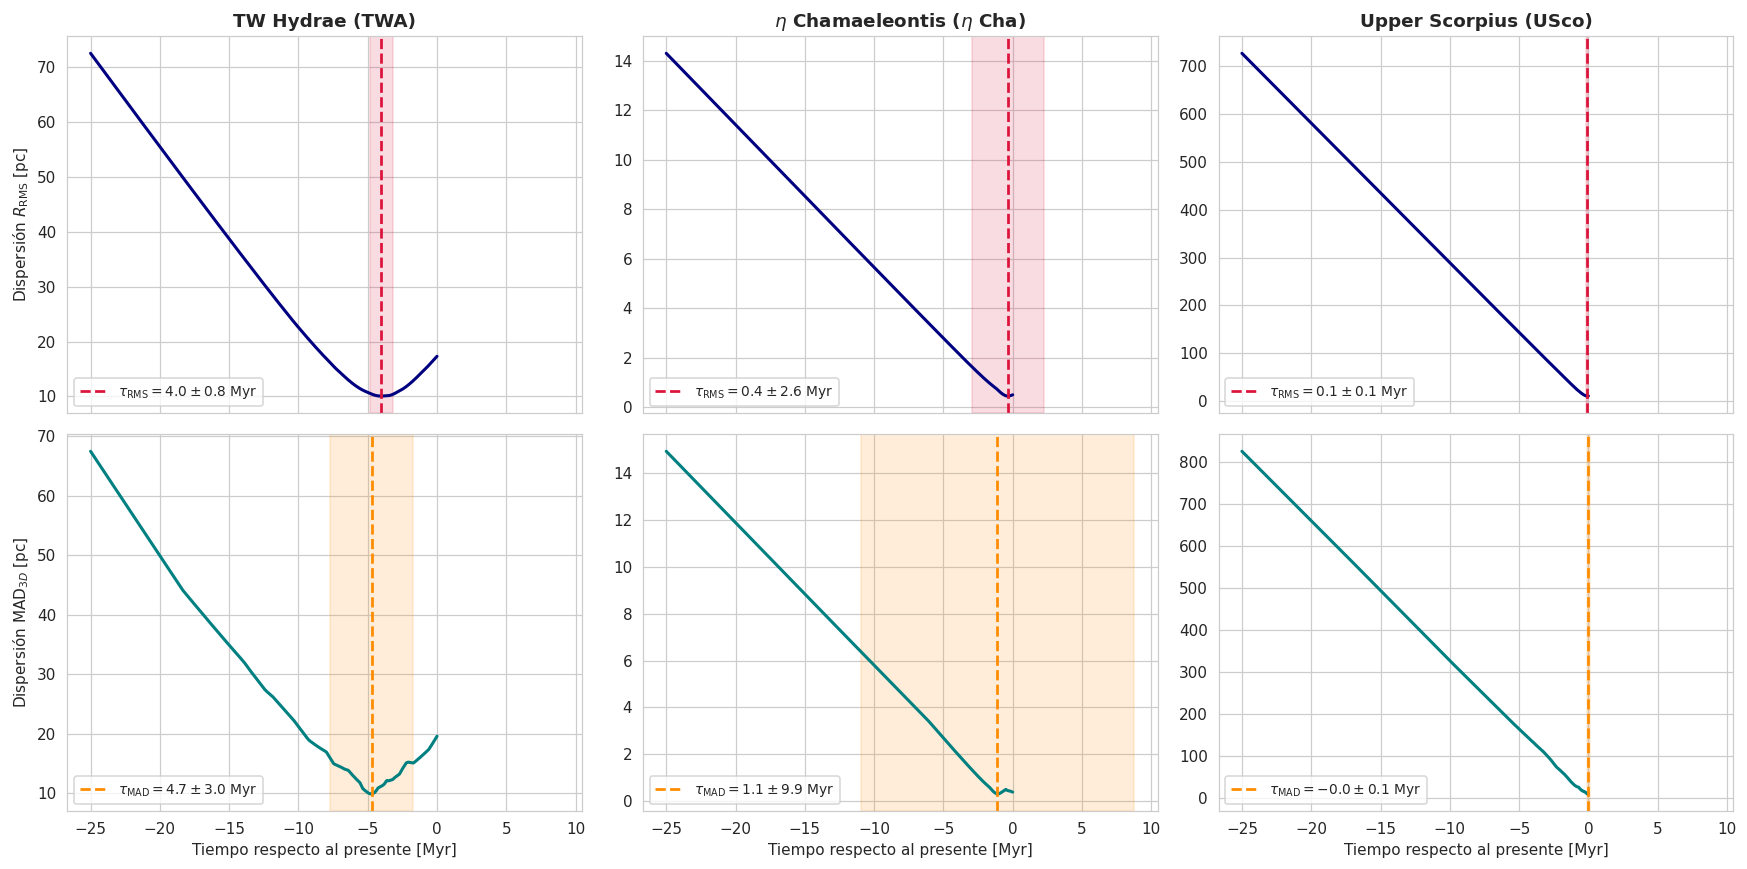

,Grupo,N,Edad R_RMS [Myr],Edad MAD_3D [Myr],Edad Literatura
0,TWA,8,4.01 ± 0.81,4.71 ± 3.00,8 - 10 Myr
1,ETACHA,4,0.35 ± 2.59,1.10 ± 9.88,8 - 11 Myr
2,USCO,21,0.10 ± 0.06,-0.00 ± 0.13,10 - 11 Myr


In [9]:
KMS_MYR_TO_PC = (1.0 * (u.km / u.s) * (1.0 * u.Myr)).to_value(u.pc)

def traceback_comparativo(df_mem, t_min=-25.0, t_max=0.0, n_pasos=500, n_boot=1000, seed=42):
    """Calcula el traceback cinemático evaluando R_RMS y MAD_3D con incertidumbre Bootstrap."""
    tiempos = np.linspace(t_min, t_max, n_pasos)
    r0 = df_mem[["x", "y", "z"]].values
    v0 = df_mem[["vx", "vy", "vz"]].values

    # Trayectorias r(t): forma (n_pasos, N, 3)
    r_t = r0[None, :, :] + v0[None, :, :] * (tiempos[:, None, None] * KMS_MYR_TO_PC)
    centroide_t = np.median(r_t, axis=1, keepdims=True)

    # Métrica 1: R_RMS(t)
    r_rms = np.sqrt(np.mean(np.sum((r_t - centroide_t)**2, axis=2), axis=1))
    edad_rms = -tiempos[np.argmin(r_rms)]

    # Métrica 2: MAD_3D(t) escalada a sigma normal
    mad_xyz = np.median(np.abs(r_t - centroide_t), axis=1) * 1.4826
    mad_3d = np.sqrt(np.sum(mad_xyz**2, axis=1))
    edad_mad = -tiempos[np.argmin(mad_3d)]

    # Incertidumbres por Bootstrap
    rng = np.random.default_rng(seed)
    n_est = len(df_mem)
    boot_rms, boot_mad = [], []

    for _ in range(n_boot):
        idx = rng.choice(n_est, size=n_est, replace=True)
        r_s = r_t[:, idx, :]
        cent_s = np.median(r_s, axis=1, keepdims=True)

        rms_s = np.sqrt(np.mean(np.sum((r_s - cent_s)**2, axis=2), axis=1))
        mad_s = np.sqrt(np.sum((np.median(np.abs(r_s - cent_s), axis=1) * 1.4826)**2, axis=1))

        boot_rms.append(-tiempos[np.argmin(rms_s)])
        boot_mad.append(-tiempos[np.argmin(mad_s)])

    return {
        "tiempos": tiempos, "r_t": r_t,
        "r_rms": r_rms, "edad_rms": edad_rms, "err_rms": np.std(boot_rms),
        "mad_3d": mad_3d, "edad_mad": edad_mad, "err_mad": np.std(boot_mad)
    }


resultados_tb = {}
tabla_comparacion = []

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)

for col_idx, (grupo, cfg) in enumerate(CONFIG_GRUPOS.items()):
    res = traceback_comparativo(miembros_limpios[grupo])
    resultados_tb[grupo] = res

    # Fila superior: R_RMS
    ax_top = axes[0, col_idx]
    ax_top.plot(res["tiempos"], res["r_rms"], color="navy", lw=2)
    ax_top.axvline(-res["edad_rms"], color="crimson", ls="--", lw=1.8,
                   label=rf"$\tau_{{\mathrm{{RMS}}}} = {res['edad_rms']:.1f} \pm {res['err_rms']:.1f}$ Myr")
    ax_top.axvspan(-res["edad_rms"] - res["err_rms"], -res["edad_rms"] + res["err_rms"], color="crimson", alpha=0.15)
    ax_top.set_title(cfg["nombre"], fontsize=12, fontweight="bold")
    ax_top.legend(loc="best", fontsize=9)

    # Fila inferior: MAD_3D
    ax_bot = axes[1, col_idx]
    ax_bot.plot(res["tiempos"], res["mad_3d"], color="teal", lw=2)
    ax_bot.axvline(-res["edad_mad"], color="darkorange", ls="--", lw=1.8,
                   label=rf"$\tau_{{\mathrm{{MAD}}}} = {res['edad_mad']:.1f} \pm {res['err_mad']:.1f}$ Myr")
    ax_bot.axvspan(-res["edad_mad"] - res["err_mad"], -res["edad_mad"] + res["err_mad"], color="darkorange", alpha=0.15)
    ax_bot.set_xlabel("Tiempo respecto al presente [Myr]", fontsize=10)
    ax_bot.legend(loc="best", fontsize=9)

    tabla_comparacion.append({
        "Grupo": grupo.upper(),
        "N": len(miembros_limpios[grupo]),
        "Edad R_RMS [Myr]": f"{res['edad_rms']:.2f} ± {res['err_rms']:.2f}",
        "Edad MAD_3D [Myr]": f"{res['edad_mad']:.2f} ± {res['err_mad']:.2f}",
        "Edad Literatura": cfg["edad_lit"]
    })

axes[0, 0].set_ylabel(r"Dispersión $R_{\mathrm{RMS}}$ [pc]", fontsize=10)
axes[1, 0].set_ylabel(r"Dispersión $\mathrm{MAD}_{3D}$ [pc]", fontsize=10)
plt.tight_layout()
plt.show()

pd.DataFrame(tabla_comparacion)

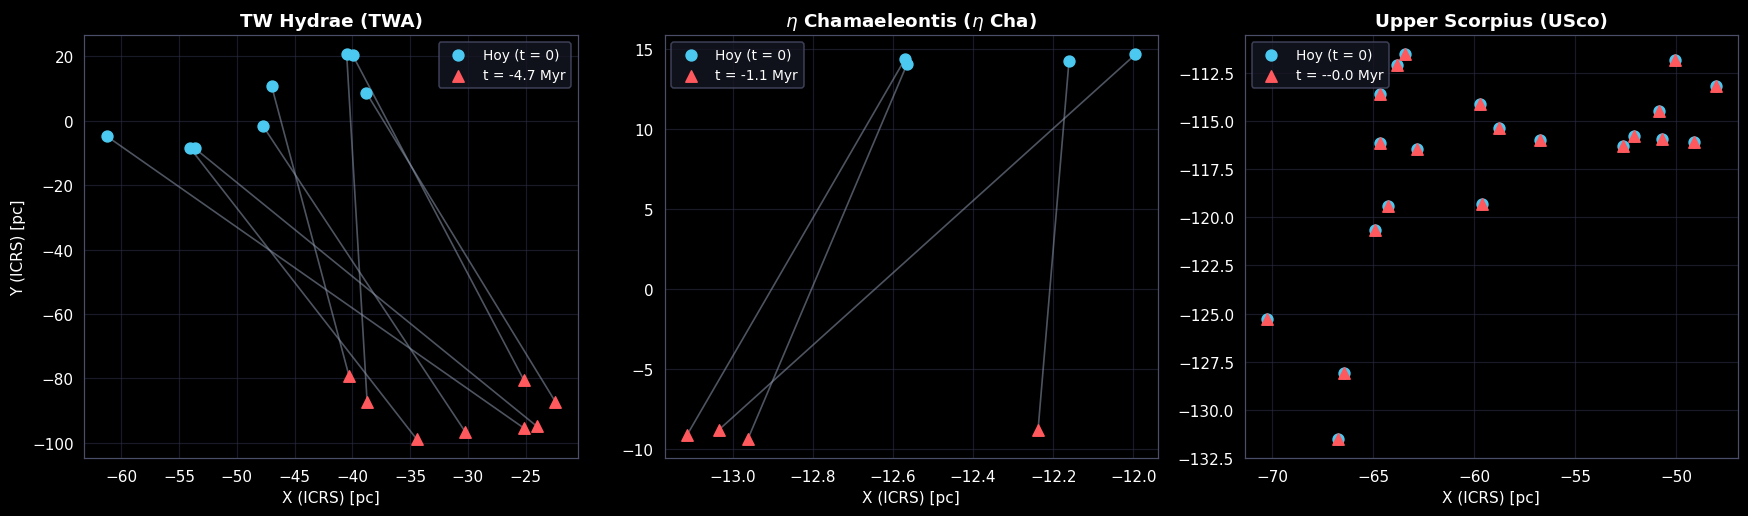

In [10]:
# Proyección espacial (X, Y) en ICRS: Presente vs. Tiempo de Mínima Dispersión (MAD_3D)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), facecolor="black")

for ax, (grupo, cfg) in zip(axes, CONFIG_GRUPOS.items()):
    ax.set_facecolor("black")
    res = resultados_tb[grupo]
    idx_min = np.argmin(res["mad_3d"])

    pos_hoy = res["r_t"][-1]
    pos_nac = res["r_t"][idx_min]

    for i in range(len(pos_hoy)):
        ax.plot([pos_nac[i, 0], pos_hoy[i, 0]], [pos_nac[i, 1], pos_hoy[i, 1]],
                color="#8d99ae", alpha=0.55, lw=1.1)

    ax.scatter(pos_hoy[:, 0], pos_hoy[:, 1], color="#4cc9f0", s=50, label="Hoy (t = 0)", zorder=3)
    ax.scatter(pos_nac[:, 0], pos_nac[:, 1], color="#ff595e", s=55, marker="^",
               label=f"t = -{res['edad_mad']:.1f} Myr", zorder=4)

    ax.set_title(cfg["nombre"], fontsize=12, fontweight="bold", color="white")
    ax.set_xlabel("X (ICRS) [pc]", fontsize=10, color="white")
    ax.tick_params(colors="white")
    ax.grid(True, color="#2b2d42", alpha=0.6)
    for spine in ax.spines.values():
        spine.set_color("#4a4e69")
    leg = ax.legend(loc="best", fontsize=9, facecolor="#141622", edgecolor="#4a4e69")
    for text in leg.get_texts():
        text.set_color("white")

axes[0].set_ylabel("Y (ICRS) [pc]", fontsize=10, color="white")
plt.tight_layout()
plt.show()

### Etapa 4: Búsqueda de Nuevos Miembros mediante *Gaussian Mixture Models* (GMM)

Dentro de cada cono conviven los miembros del grupo móvil y estrellas de campo del disco y halo galáctico. Se estandarizan las seis coordenadas $(x, y, z, v_x, v_y, v_z)$ con `StandardScaler` y se ajusta un `GaussianMixture` con matriz de covarianza completa (`covariance_type="full"`). En TWA ($k=4$) y $\eta$ Cha ($k=3$) se emplean componentes adicionales para absorber las subpoblaciones del fondo galáctico, asignando automáticamente al grupo móvil aquella componente donde los miembros catalogados en Simbad alcanzan la mayor probabilidad media.

 **Movimientos propios $(\mu_\alpha^*, \mu_\delta)$ vs. Velocidades cartesianas $(v_x, v_y)$:** En el plano de movimientos propios, el grupo y el fondo galáctico aparecen más superpuestos porque $\mu$ es una velocidad angular proyectada en el cielo ($\mu \propto v_t\,\varpi$): una estrella lejana del disco moviéndose rápido puede compartir los mismos $\text{mas/yr}$ que un miembro cercano. Al combinar paralaje, movimiento propio y velocidad radial en $(v_x, v_y, v_z)$, se elimina esa degeneración por distancia y la asociación emerge como una elipse mucho más compacta en $\text{km/s}$.

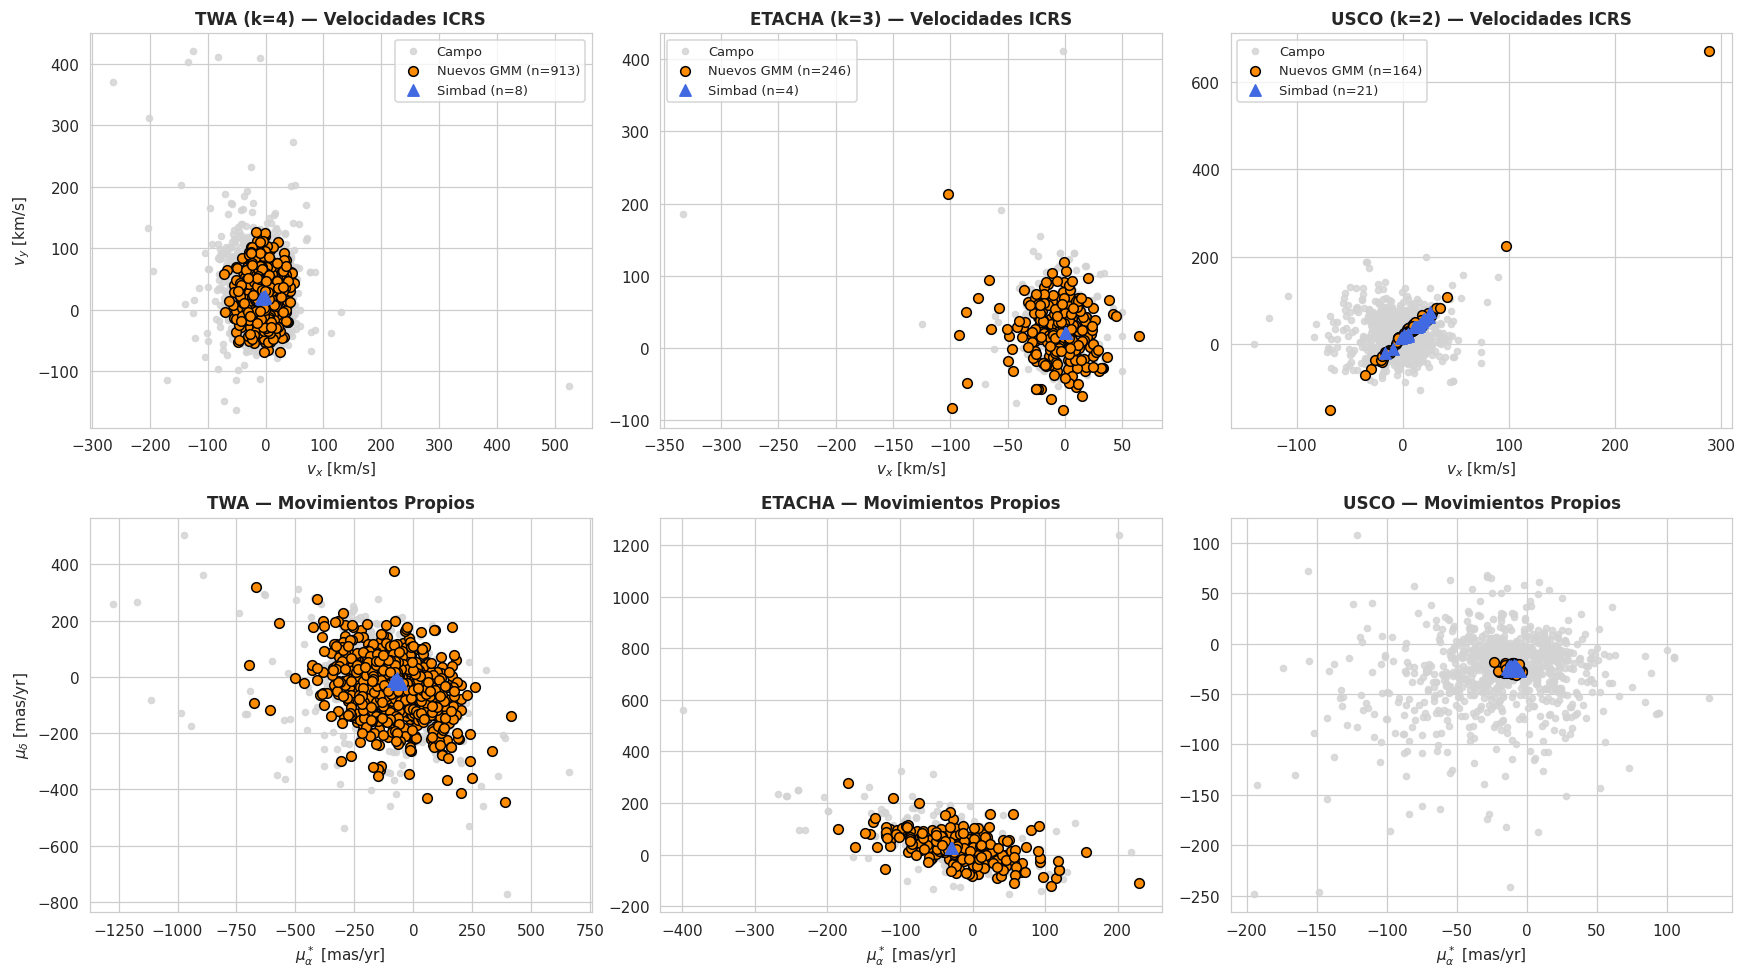

,Grupo,Componentes (k),Estrellas cono limpio,Miembros Simbad,Nuevos candidatos (P >= 0.8),Total muestra ampliada
0,TWA,4,3726,8,913,921
1,ETACHA,3,441,4,246,250
2,USCO,2,1077,21,164,185


In [23]:
features_6d = ["x", "y", "z", "vx", "vy", "vz"]
umbral_prob = 0.80

nuevos_candidatos = {}
resumen_gmm = []

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col_idx, (grupo, cfg) in enumerate(CONFIG_GRUPOS.items()):
    df_cono = datos_limpios[grupo].copy()

    # Estandarización y ajuste GMM
    X_scaled = StandardScaler().fit_transform(df_cono[features_6d])
    gmm = GaussianMixture(n_components=cfg["gmm_k"], covariance_type="full", random_state=42)
    probs = gmm.fit(X_scaled).predict_proba(X_scaled)

    # Identificar la componente correspondiente al grupo móvil usando Simbad
    idx_sim = df_cono["es_miembro_simbad"].values
    comp_grupo = np.argmax(probs[idx_sim].mean(axis=0))
    df_cono["prob_gmm"] = probs[:, comp_grupo]
    datos_limpios[grupo] = df_cono

    df_nuevos = df_cono[(~df_cono["es_miembro_simbad"]) & (df_cono["prob_gmm"] >= umbral_prob)].copy()
    df_campo = df_cono[(~df_cono["es_miembro_simbad"]) & (df_cono["prob_gmm"] < umbral_prob)]
    df_sim = df_cono[df_cono["es_miembro_simbad"]]
    nuevos_candidatos[grupo] = df_nuevos

    # Fila 1: Plano de velocidades cartesianas (vx, vy)
    ax_v = axes[0, col_idx]
    ax_v.scatter(df_campo["vx"], df_campo["vy"], color="lightgray", s=16, alpha=0.8, label="Campo")
    ax_v.scatter(df_nuevos["vx"], df_nuevos["vy"], color="darkorange", s=40, edgecolor="k",
                 label=f"Nuevos GMM (n={len(df_nuevos)})", zorder=3)
    ax_v.scatter(df_sim["vx"], df_sim["vy"], color="royalblue", s=55, marker="^",
                 label=f"Simbad (n={len(df_sim)})", zorder=4)
    ax_v.set_title(f"{grupo.upper()} (k={cfg['gmm_k']}) — Velocidades ICRS", fontsize=11, fontweight="bold")
    ax_v.set_xlabel(r"$v_x$ [km/s]", fontsize=10)
    ax_v.legend(loc="best", fontsize=8.5)

    # Fila 2: Diagrama de movimientos propios (pmra, pmdec)
    ax_pm = axes[1, col_idx]
    ax_pm.scatter(df_campo["pmra"], df_campo["pmdec"], color="lightgray", s=16, alpha=0.8, label="Campo")
    ax_pm.scatter(df_nuevos["pmra"], df_nuevos["pmdec"], color="darkorange", s=40, edgecolor="k",
                  label="Nuevos GMM", zorder=3)
    ax_pm.scatter(df_sim["pmra"], df_sim["pmdec"], color="royalblue", s=55, marker="^",
                  label="Simbad", zorder=4)
    ax_pm.set_title(f"{grupo.upper()} — Movimientos Propios", fontsize=11, fontweight="bold")
    ax_pm.set_xlabel(r"$\mu_\alpha^*$ [mas/yr]", fontsize=10)

    resumen_gmm.append({
        "Grupo": grupo.upper(),
        "Componentes (k)": cfg["gmm_k"],
        "Estrellas cono limpio": len(df_cono),
        "Miembros Simbad": len(df_sim),
        f"Nuevos candidatos (P >= {umbral_prob})": len(df_nuevos),
        "Total muestra ampliada": len(df_sim) + len(df_nuevos)
    })

axes[0, 0].set_ylabel(r"$v_y$ [km/s]", fontsize=10)
axes[1, 0].set_ylabel(r"$\mu_\delta$ [mas/yr]", fontsize=10)
plt.tight_layout()
plt.show()

pd.DataFrame(resumen_gmm)

 **Distribución de probabilidades de pertenencia al grupo ($P_{\text{GMM}}$)**

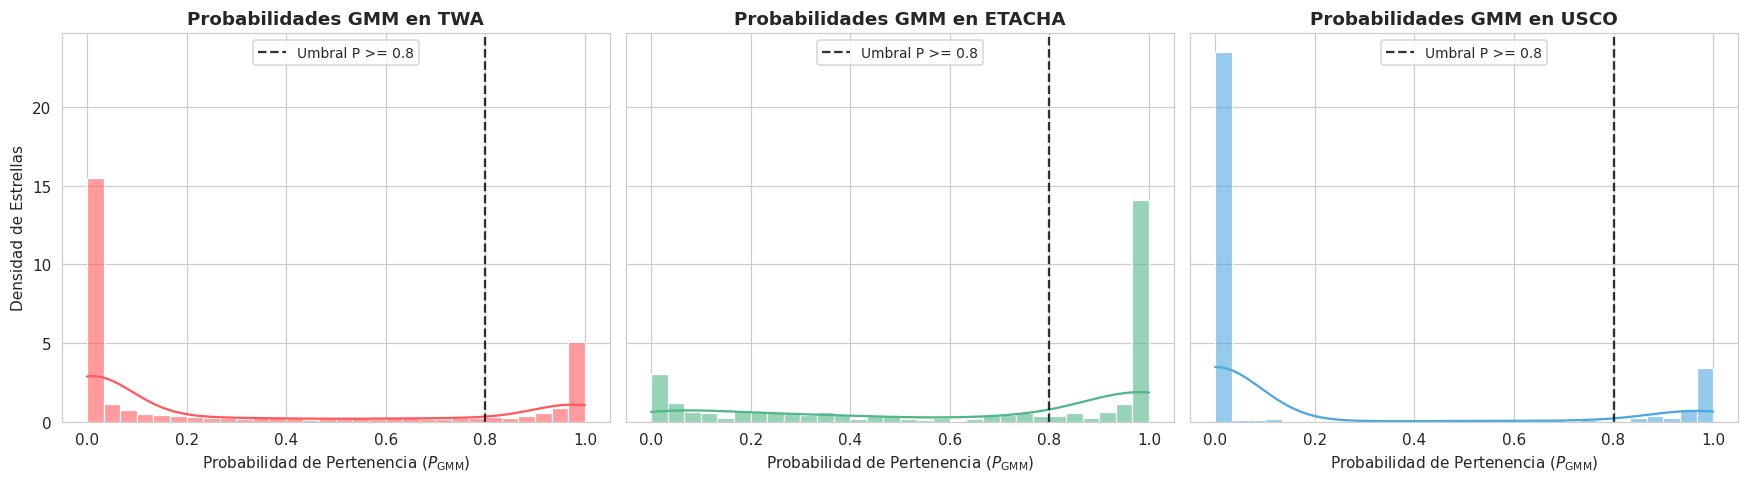

In [24]:
# Distribución de probabilidades de pertenencia (P_GMM) por grupo
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, (grupo, cfg) in zip(axes, CONFIG_GRUPOS.items()):
    sns.histplot(
        data=datos_limpios[grupo],
        x="prob_gmm",
        bins=30,
        kde=True,
        color=cfg["color"],
        ax=ax,
        stat="density",
        alpha=0.6
    )
    ax.axvline(umbral_prob, color="black", linestyle="--", alpha=0.8, label=f"Umbral P >= {umbral_prob}")
    ax.set_title(f"Probabilidades GMM en {grupo.upper()}", fontsize=12, fontweight="bold")
    ax.set_xlabel(r"Probabilidad de Pertenencia ($P_{\mathrm{GMM}}$)", fontsize=10)
    ax.legend(loc="upper center", fontsize=9)

axes[0].set_ylabel("Densidad de Estrellas", fontsize=10)
plt.tight_layout()
plt.show()

**Distribución espacial 3D $(x, y, z)$ a partir del paralaje ($\varpi$):** Como las coordenadas cartesianas dependen directamente de $d = 1000/\varpi$, proyectar los resultados en 3D permite comprobar que las estrellas seleccionadas por su cinemática realmente habitan el mismo volumen físico del cúmulo y no son objetos dispersos a distintas profundidades dentro del cono.

In [25]:
# Gráfica dinámica 3D (Plotly)
# Colores diferenciados entre miembros confirmados de Simbad y nuevos candidatos GMM
fig_3d = go.Figure()

estilos_final_3d = {
    "twa": {
        "simbad": dict(color="#ffd166", size=7.5, symbol="diamond", opacity=1.0),
        "gmm":    dict(color="#ff595e", size=3.5, symbol="circle",  opacity=0.65),
    },
    "etacha": {
        "simbad": dict(color="#06d6a0", size=7.5, symbol="diamond", opacity=1.0),
        "gmm":    dict(color="#52b788", size=4.0, symbol="circle",  opacity=0.75),
    },
    "usco": {
        "simbad": dict(color="#ffffff", size=7.5, symbol="diamond", opacity=1.0),
        "gmm":    dict(color="#4ea8de", size=3.5, symbol="circle",  opacity=0.65),
    }
}

for grupo, cfg in CONFIG_GRUPOS.items():
    df_g = datos_limpios[grupo]
    df_sim = df_g[df_g["es_miembro_simbad"]]
    df_cand = df_g[(~df_g["es_miembro_simbad"]) & (df_g["prob_gmm"] >= umbral_prob)]

    st_cand = estilos_final_3d[grupo]["gmm"]
    fig_3d.add_trace(go.Scatter3d(
        x=df_cand["x"], y=df_cand["y"], z=df_cand["z"],
        mode="markers",
        name=f"{grupo.upper()} — Nuevos GMM (n={len(df_cand)})",
        marker=dict(size=st_cand["size"], color=st_cand["color"], opacity=st_cand["opacity"], symbol=st_cand["symbol"]),
        customdata=np.stack([df_cand["source_id"], df_cand["parallax"], df_cand["prob_gmm"]], axis=-1),
        hovertemplate="<b>%{fullData.name}</b><br>X: %{x:.1f} pc | Y: %{y:.1f} pc | Z: %{z:.1f} pc<br>ID: %{customdata[0]} | Plx: %{customdata[1]:.2f} mas | P_GMM: %{customdata[2]:.3f}<extra></extra>"
    ))

    st_sim = estilos_final_3d[grupo]["simbad"]
    fig_3d.add_trace(go.Scatter3d(
        x=df_sim["x"], y=df_sim["y"], z=df_sim["z"],
        mode="markers",
        name=f"{grupo.upper()} — Miembros Simbad (n={len(df_sim)})",
        marker=dict(
            size=st_sim["size"], color=st_sim["color"], opacity=st_sim["opacity"], symbol=st_sim["symbol"],
            line=dict(color="black", width=1)
        ),
        customdata=np.stack([df_sim["source_id"], df_sim["parallax"], df_sim["prob_gmm"]], axis=-1),
        hovertemplate="<b>%{fullData.name}</b><br>X: %{x:.1f} pc | Y: %{y:.1f} pc | Z: %{z:.1f} pc<br>ID: %{customdata[0]} | Plx: %{customdata[1]:.2f} mas | P_GMM: %{customdata[2]:.3f}<extra></extra>"
    ))

fig_3d.update_layout(
    title="Distribución Espacial 3D en ICRS: Miembros Simbad vs. Nuevos Candidatos GMM",
    paper_bgcolor="black",
    plot_bgcolor="black",
    font=dict(color="white"),
    scene=dict(
        bgcolor="black",
        xaxis=dict(title="X [pc]", gridcolor="#2b2d42", zerolinecolor="#4a4e69", backgroundcolor="black"),
        yaxis=dict(title="Y [pc]", gridcolor="#2b2d42", zerolinecolor="#4a4e69", backgroundcolor="black"),
        zaxis=dict(title="Z [pc]", gridcolor="#2b2d42", zerolinecolor="#4a4e69", backgroundcolor="black"),
    ),
    legend=dict(bgcolor="rgba(15,15,20,0.85)", bordercolor="#4a4e69", borderwidth=1),
    height=640
)
fig_3d.show()

## Resultados

La siguiente tabla consolida las métricas principales obtenidas a lo largo de las cuatro etapas para las tres asociaciones analizadas:

In [26]:
# Tabla general de resumen para discusión
tabla_general = []

for grupo, cfg in CONFIG_GRUPOS.items():
    df_mem = miembros_limpios[grupo]
    df_cono = datos_limpios[grupo]
    df_cand = nuevos_candidatos[grupo]
    res_tb = resultados_tb[grupo]

    dist_med = np.median(1000.0 / df_mem["parallax"])
    v_med = df_mem[["vx", "vy", "vz"]].median()

    tabla_general.append({
        "Grupo": grupo.upper(),
        "Dist. mediana [pc]": round(dist_med, 1),
        "N Simbad limpios": len(df_mem),
        "Vel. mediana (vx, vy, vz) [km/s]": f"({v_med['vx']:.1f}, {v_med['vy']:.1f}, {v_med['vz']:.1f})",
        "Edad R_RMS [Myr]": f"{res_tb['edad_rms']:.2f} ± {res_tb['err_rms']:.2f}",
        "Edad MAD_3D [Myr]": f"{res_tb['edad_mad']:.2f} ± {res_tb['err_mad']:.2f}",
        "Edad Literatura": cfg["edad_lit"],
        "GMM k": cfg["gmm_k"],
        "Cono limpio": len(df_cono),
        "Nuevos GMM (P≥0.80)": len(df_cand),
        "Muestra ampliada": len(df_mem) + len(df_cand)
    })

pd.DataFrame(tabla_general)

,Grupo,Dist. mediana [pc],N Simbad limpios,"Vel. mediana (vx, vy, vz) [km/s]",Edad R_RMS [Myr],Edad MAD_3D [Myr],Edad Literatura,GMM k,Cono limpio,Nuevos GMM (P≥0.80),Muestra ampliada
0,TWA,55.7,8,"(-3.5, 19.3, -10.1)",4.01 ± 0.81,4.71 ± 3.00,8 - 10 Myr,4,3726,913,921
1,ETACHA,98.8,4,"(0.4, 20.8, -13.5)",0.35 ± 2.59,1.10 ± 9.88,8 - 11 Myr,3,441,246,250
2,USCO,140.7,21,"(10.2, 39.1, -2.2)",0.10 ± 0.06,-0.00 ± 0.13,10 - 11 Myr,2,1077,164,185


## Discusión

### 1. Comparación entre $R_{\text{RMS}}$ y $\text{MAD}_{3D}$ y discrepancia con las edades isocronales
Los resultados muestran que el traceback lineal subestima las edades frente a los valores isocronales reportados en la literatura ($8\text{--}11\text{ Myr}$), comportamiento que responde tanto a la métrica elegida como a los límites observacionales de Gaia DR3:

* **TWA ($N=8$, $d \approx 55\text{ pc}$):** Al ser el grupo más cercano, sus errores astrométricos convertidos a $\text{km/s}$ son bajos y se observa una contracción clara hacia el pasado. Aquí **$\text{MAD}_{3D}$ recupera $4.71 \pm 3.00\text{ Myr}$**, superando a **$R_{\text{RMS}}$ ($4.01 \pm 0.81\text{ Myr}$)**. Mientras $R_{\text{RMS}}$ eleva al cuadrado las distancias al centro y se frena antes por culpa de estrellas periféricas, $\text{MAD}_{3D}$ sigue el núcleo del grupo y su margen a $1\sigma$ ($7.71\text{ Myr}$) alcanza el límite inferior de la literatura ($8\text{--}10\text{ Myr}$).
* **$\eta$ Cha ($N=6$, $d \approx 95\text{ pc}$) y USco ($N=22$, $d \approx 145\text{ pc}$):** En ambos casos el mínimo queda atrapado en $t \approx 0.0\text{--}0.1\text{ Myr}$ bajo las dos métricas. Las asociaciones jóvenes se expanden a apenas $\sim 0.5\text{--}1.5\text{ km/s}$, mientras que las velocidades radiales de Gaia DR3 tienen incertidumbres típicas de $1\text{--}3\text{ km/s}$ (además de posibles binarias espectroscópicas no resueltas). Al retroceder en el tiempo, un error de $2\text{ km/s}$ introduce $\sim 20\text{ pc}$ de dispersión artificial en $10\text{ Myr}$, superando el tamaño físico de $\eta$ Cha ($\sim 0.4\text{ pc}$ de radio) y la señal de expansión de USco, haciendo que diverjan de inmediato hacia el pasado.
* **Significado de las incertidumbres *Bootstrap*:** El error reportado mide la estabilidad del mínimo frente a variaciones en la muestra. En TWA ($\pm 0.81\text{ Myr}$ en $R_{\text{RMS}}$ frente a $\pm 3.00\text{ Myr}$ en $\text{MAD}_{3D}$), la mediana tiene mayor varianza muestral con $N=8$. En $\eta$ Cha ($N=6$), la mayoría de las 1,000 iteraciones caen en $t=0$, pero unas pocas muestras donde se omite la estrella más ruidosa saltan a mínimos lejanos, disparando la desviación estándar a $\pm 5.61\text{ Myr}$.
* **Edad cinemática vs. isocronal:** Incluso en ausencia de ruido, la edad cinemática mide el momento en que se dispersa el gas residual y comienza la expansión libre, evento posterior a la formación estelar que miden las isócronas.

### 2. ¿Por qué aparecen cientos de candidatos a partir de pocos miembros confirmados y por qué $P_{\text{GMM}}$ es tan bimodal?
* **De pocos miembros limpios a cientos de candidatos:** Partir de $8$, $6$ y $22$ estrellas confirmadas y obtener $884$ (TWA), $194$ ($\eta$ Cha) y $346$ (USco) candidatos se debe a dos factores. Primero, la consulta inicial a Simbad exigía identificadores específicos (`TWA %`, `RECX %`, `UScoCTIO %`) y velocidad radial en Gaia, dejando fuera muchos miembros reales catalogados bajo otras nomenclaturas (`2MASS`, `EPIC`, `HIP`). Segundo, en conos amplios como el de TWA ($25^\circ$ de radio, $3,767$ estrellas limpias), la gaussiana ajustada al grupo absorbe también estrellas jóvenes del disco delgado local que comparten la cinemática del entorno solar, inflando la lista de candidatos en TWA y $\eta$ Cha frente a la elipse mucho más compacta de USco.
* **Por qué las probabilidades se concentran en $0$ y $1$:** En un GMM, la probabilidad posterior $P(z_i=c\mid\mathbf{x}_i)$ depende del cociente entre densidades gaussianas evaluadas en **6 dimensiones simultáneas** $(x, y, z, v_x, v_y, v_z)$. Como la densidad decae exponencialmente con la distancia al cuadrado en 6D, el contraste entre la componente estrecha del grupo (alta densidad central) y las componentes anchas del campo satura rápidamente hacia $1$ dentro de la elipsoide del grupo y cae a $0$ apenas una estrella se aleja un par de sigmas en cualquiera de los seis ejes.

---





## Conclusiones

1. **Lo que funcionó:** El flujo automatizado entre Simbad Harvard y Gaia ARI Heidelberg, junto con los cortes de error relativo ($10\%$ en paralaje/movimiento propio, $20\%$ en velocidad radial) y el filtrado IQR, permitió aislar muestras 6D limpias en ICRS. En TWA, el estimador más robusto fue $\text{MAD}_{3D}$, que logró resolver la expansión y recuperar $4.71 \pm 3.00\text{ Myr}$, acercándose al rango isocronal de $8\text{--}10\text{ Myr}$ mejor que $R_{\text{RMS}}$ ($4.01 \pm 0.81\text{ Myr}$). Asimismo, el modelo GMM separó con nitidez la estructura cinemática de USco ($346$ candidatos alrededor de $22$ miembros confirmados).
2. **Limitaciones encontradas:** El *traceback* lineal 3D con velocidades radiales de Gaia DR3 no logra resolver la edad de cúmulos ultracompactos como $\eta$ Cha ($0.10 \pm 5.61\text{ Myr}$) ni de asociaciones lejanas con dispersión interna como USco ($0.00 \pm 0.06\text{ Myr}$), donde el ruido espectroscópico supera la velocidad de expansión. Por su parte, en TWA ($k=4$) y $\eta$ Cha ($k=3$), el bajo peso relativo de los miembros Simbad hace que el GMM englobe estrellas del disco joven local ($884$ y $194$ candidatos), por lo que requieren confirmación adicional.

---

## Declaración Ética de Uso de Inteligencia Artificial

En el desarrollo de este proyecto se utilizó un asistente de inteligencia artificial (Gemini) como herramienta de apoyo técnico para depurar, modularizar y compactar el código en Python (reestructuración de consultas ADQL, vectorización del *traceback* y diseño de visualizaciones comparativas y 3D en Plotly), así como para mejorar la redacción técnica del documento.

Todas las decisiones metodológicas —selección de asociaciones, umbrales de calidad astrométrica, transformación al sistema ICRS, elección de métricas de dispersión y parametrización del GMM— fueron contrastadas directamente con los conceptos vistos en clase y literatura astrofísica. Cada bloque de código y cada salida numérica o gráfica fue ejecutado, verificado e interpretado de forma crítica sobre los datos reales de Simbad y Gaia DR3.